### Notebook 03: Model C4.5 (Model Utama)

#### 1. Persiapan

##### 1.1 Pustaka

In [1]:
import importlib
import json
import platform
import sys
import time
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn
from sklearn.tree import DecisionTreeClassifier

print("Python       :", platform.python_version())
print("NumPy        :", np.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("matplotlib   :", matplotlib.__version__)

Python       : 3.10.6
NumPy        : 1.26.4
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.2


##### 1.2 Konfigurasi

In [2]:
def find_ml_dir(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "c45.py").exists():
            return folder
        if (folder / "ml" / "src" / "c45.py").exists():
            return folder / "ml"
    raise FileNotFoundError("Folder ml/ tidak ditemukan. Buka notebook ini dari dalam repo Nutrify.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

from src import c45, evaluation as ev

importlib.reload(c45)
importlib.reload(ev)

SEED = 42
CLASS_WEIGHT = "balanced"
LEARNING_FRACTIONS = (0.2, 0.4, 0.6, 0.8, 1.0)
PERMUTATION_REPEATS = 30
N_BOOTSTRAP = 2000
GALLERY_SIZE = 12
CONFIDENCE_BINS = (0.0, 0.6, 0.8, 0.95, 1.0001)
TRAIN_TIMING_REPEATS = 20
PREDICT_TIMING_REPEATS = 5

RAW_DIR = ML_DIR / "data" / "raw"
PROCESSED_DIR = ML_DIR / "data" / "processed"
FIGURES_DIR = ML_DIR / "reports" / "figures"
TABLES_DIR = ML_DIR / "reports" / "tables"
RESULTS_DIR = ML_DIR / "reports" / "results"
MODELS_DIR = ML_DIR / "models" / "candidates"
for folder in (FIGURES_DIR, TABLES_DIR, RESULTS_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ev.CLASSES
CLASS_LABEL_ID = ev.CLASS_LABEL_ID
CLASS_COLORS = ev.CLASS_COLORS
FEATURE_SETS = ev.FEATURE_SETS
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})


def save_figure(fig, name: str) -> None:
    fig.savefig(FIGURES_DIR / name, bbox_inches="tight")


print("Folder ml/ :", ML_DIR)

Folder ml/ : D:\LARAGON\www\nutrify\ml


##### 1.3 Perangkat keras

In [3]:
HARDWARE = {
    "Laptop": "Lenovo LOQ 15IAX9",
    "CPU": "Intel Core i5-12450HX, 2.40 GHz",
    "RAM": "12 GB DDR5 (11,7 GB dapat dipakai)",
    "GPU": "Tidak dipakai (RTX 3050 tersedia, scikit-learn berjalan di CPU)",
    "Sistem": "Windows 11 Home, 64-bit",
}
hardware_table = pd.Series(
    {
        **HARDWARE,
        "Python": platform.python_version(),
        "Sistem terdeteksi": f"{platform.system()} {platform.release()}",
        "Inti logis CPU": psutil.cpu_count(logical=True),
        "RAM terdeteksi (GB)": round(psutil.virtual_memory().total / 1024 ** 3, 1),
    },
    name="nilai",
).to_frame()
display(hardware_table)

,nilai
Laptop,Lenovo LOQ 15IAX9
CPU,"Intel Core i5-12450HX, 2.40 GHz"
RAM,"12 GB DDR5 (11,7 GB dapat dipakai)"
GPU,"Tidak dipakai (RTX 3050 tersedia, scikit-learn..."
Sistem,"Windows 11 Home, 64-bit"
Python,3.10.6
Sistem terdeteksi,Windows 10
Inti logis CPU,12
RAM terdeteksi (GB),11.7


#### 2. Data

##### 2.1 Pemuatan data latih

In [4]:
train = ev.load_partition(ML_DIR, "train")

assert set(train["origin"]) == {"roboflow"}
assert train["image_id"].is_unique
assert set(train["label"]) == set(CLASSES)

data_summary = (
    train.groupby("label")
    .agg(berkas=("image_id", "size"), foto_sumber=("source_group", "nunique"))
    .reindex(CLASSES)
)
data_summary.index = [CLASS_LABEL_ID[c] for c in data_summary.index]
data_summary.loc["Total"] = data_summary.sum()
data_summary.to_csv(TABLES_DIR / "03_train_summary.csv")
display(data_summary)

,berkas,foto_sumber
Normal,92,57
Defisiensi N,70,16
Defisiensi Fe,142,35
Total,304,108


##### 2.2 Himpunan fitur

In [5]:
feature_set_table = pd.DataFrame(
    {"himpunan": list(FEATURE_SETS), "jumlah_fitur": [len(f) for f in FEATURE_SETS.values()], "fitur": [", ".join(f) for f in FEATURE_SETS.values()]}
).set_index("himpunan")
display(feature_set_table)

,jumlah_fitur,fitur
himpunan,,
A1,3,"Mean_R, Mean_G, Mean_B"
A2,6,"Mean_R, Mean_G, Mean_B, Lab_L, Lab_a, Lab_b"


##### 2.3 Sebaran fitur per kelas

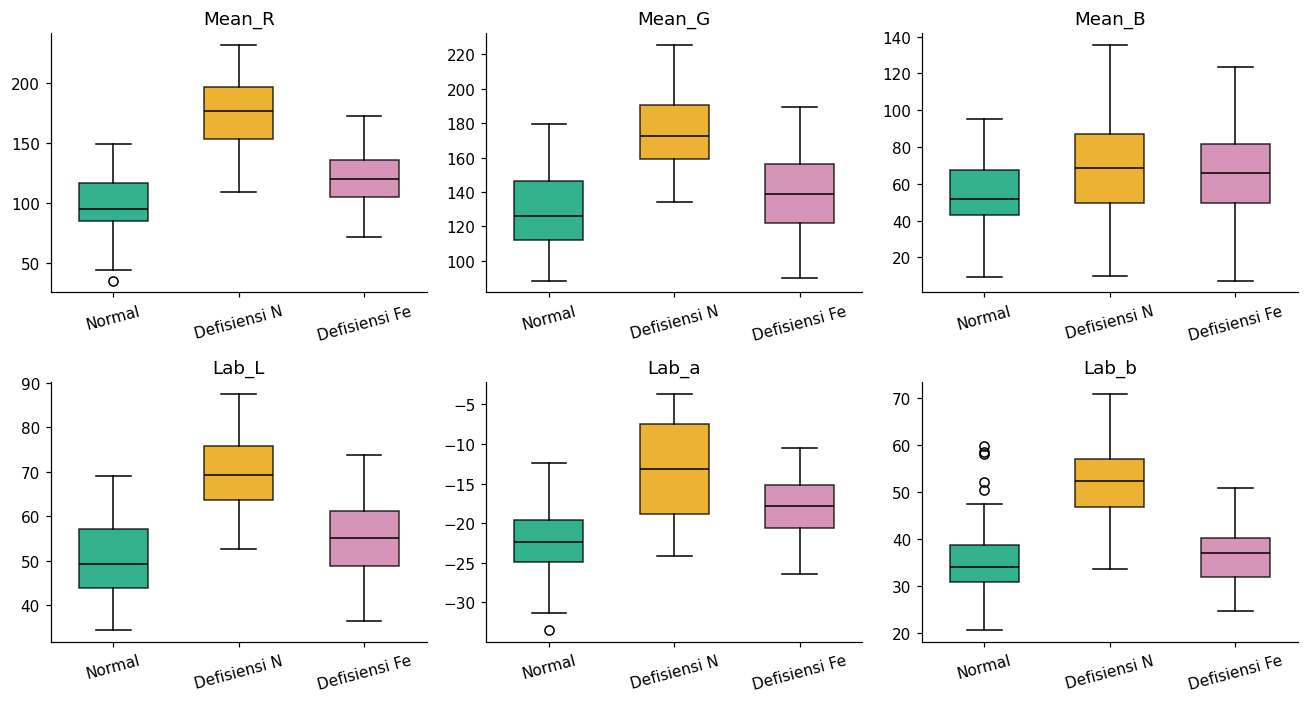

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, feature in zip(axes.ravel(), FEATURE_SETS["A2"]):
    data = [train.loc[train["label"] == c, feature] for c in CLASSES]
    boxes = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops={"color": "black"})
    for patch, c in zip(boxes["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLORS[c])
        patch.set_alpha(0.8)
    ax.set_xticks(range(1, 4), [CLASS_LABEL_ID[c] for c in CLASSES], rotation=15)
    ax.set_title(feature)
fig.tight_layout()
save_figure(fig, "03_feature_distribution.png")
plt.show()

##### 2.4 Statistik fitur per kelas

In [7]:
feature_stats = train.groupby("label")[FEATURE_SETS["A2"]].agg(["mean", "std", "min", "max"]).reindex(CLASSES).round(2)
feature_stats.index = [CLASS_LABEL_ID[c] for c in feature_stats.index]
feature_stats.to_csv(TABLES_DIR / "03_feature_statistics.csv")
display(feature_stats)

Mean_R                       Mean_G                       \
                 mean    std    min    max    mean    std    min    max   
Normal         100.21  23.02   35.7  149.5  128.27  22.73   88.4  179.4   
Defisiensi N   175.95  29.08  109.8  231.9  175.36  22.12  133.9  225.7   
Defisiensi Fe  121.78  23.05   72.3  172.6  139.30  22.18   89.8  189.3   

              Mean_B         ... Lab_L        Lab_a                    Lab_b  \
                mean    std  ...   min   max   mean   std   min   max   mean   
Normal         54.67  20.44  ...  34.4  69.0 -22.22  4.10 -33.5 -12.4  35.37   
Defisiensi N   68.76  27.08  ...  52.5  87.4 -13.16  5.94 -24.1  -3.7  51.90   
Defisiensi Fe  65.69  23.98  ...  36.5  73.8 -17.80  3.50 -26.4 -10.5  36.28   

                                 
                std   min   max  
Normal         7.38  20.7  59.9  
Defisiensi N   7.94  33.6  70.9  
Defisiensi Fe  6.05  24.7  51.0  

[3 rows x 24 columns]

#### 3. Landasan Matematis C4.5

##### 3.1 Entropi dan perolehan informasi

$$
H(S) = -\sum_{i=1}^{K} p_i \log_2 p_i, \qquad p_i = \frac{n_i}{|S|}
$$

$$
\mathrm{Gain}(S, A, t) = H(S) - \frac{|S_{\le}|}{|S|}\, H(S_{\le}) - \frac{|S_{>}|}{|S|}\, H(S_{>})
$$

dengan $S_{\le} = \{x \in S : x_A \le t\}$ dan $S_{>} = S \setminus S_{\le}$.

##### 3.2 Rasio perolehan

$$
\mathrm{SplitInfo}(S, A, t) = -\frac{|S_{\le}|}{|S|}\log_2\frac{|S_{\le}|}{|S|} - \frac{|S_{>}|}{|S|}\log_2\frac{|S_{>}|}{|S|}
$$

$$
\mathrm{GainRatio}(S, A, t) = \frac{\mathrm{Gain}(S, A, t)}{\mathrm{SplitInfo}(S, A, t)}
$$

##### 3.3 Ambang untuk atribut kontinu

Nilai atribut diurutkan menjadi $v_1 < v_2 < \dots < v_m$. Kandidat ambang adalah titik tengah antara dua nilai bertetangga yang kelasnya berbeda:

$$
t_j = \frac{v_j + v_{j+1}}{2}
$$

Untuk setiap atribut dipilih ambang dengan $\mathrm{Gain}$ tertinggi, $t_A^{*} = \arg\max_t \mathrm{Gain}(S, A, t)$.

##### 3.4 Aturan pemilihan atribut

$$
\overline{\mathrm{Gain}} = \frac{1}{|\mathcal{A}|}\sum_{A \in \mathcal{A}} \mathrm{Gain}(S, A, t_A^{*}), \qquad
A^{*} = \operatorname*{arg\,max}_{A:\ \mathrm{Gain}(S, A, t_A^{*}) \ge \overline{\mathrm{Gain}}} \mathrm{GainRatio}(S, A, t_A^{*})
$$

##### 3.5 Pembobotan kelas

$$
w_c = \frac{n}{K\, n_c}, \qquad p_i = \frac{\sum_{x \in S,\, y = i} w_{y}}{\sum_{x \in S} w_{y}}
$$

##### 3.6 Pra-pemangkasan

Simpul berhenti tumbuh jika $d \ge d_{\max}$, jika $|S| < 2m$, atau jika tidak ada pemisahan dengan $|S_{\le}| \ge m$ dan $|S_{>}| \ge m$, dengan $m$ sebagai sampel minimum per daun.

##### 3.7 Pasca-pemangkasan berbasis galat pesimistik

Untuk simpul dengan $N$ sampel dan $E$ galat, dan $z = \Phi^{-1}(1 - \mathrm{CF})$:

$$
U_{\mathrm{CF}}(E, N) = \frac{E + \tfrac{1}{2} + \tfrac{z^2}{2} + z\sqrt{\left(E + \tfrac{1}{2}\right)\left(1 - \dfrac{E + \tfrac{1}{2}}{N}\right) + \tfrac{z^2}{4}}}{N + z^2}, \qquad \hat{e}(t) = N\, U_{\mathrm{CF}}(E, N)
$$

Subpohon di simpul $t$ diganti daun jika

$$
\hat{e}(t) \le \sum_{s \in \text{daun}(t)} \hat{e}(s) + 0{,}1
$$

##### 3.8 Kepercayaan daun

$$
\mathrm{konf}(\ell) = \frac{n_{\ell, \hat{c}}}{n_{\ell}}
$$

##### 3.9 Metrik klasifikasi

$$
P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c}, \qquad F1_{\text{makro}} = \frac{1}{K}\sum_{c=1}^{K} F1_c
$$

#### 4. Pemilihan Simpul Akar

##### 4.1 Gain ratio setiap fitur pada simpul akar

In [8]:
CLASS_INDEX = {c: i for i, c in enumerate(CLASSES)}
y_index = np.array([CLASS_INDEX[v] for v in train["label"]])
class_counts = np.bincount(y_index, minlength=len(CLASSES)).astype(float)
balanced_weights = (len(y_index) / (len(CLASSES) * class_counts))[y_index]


def root_table(features):
    X = train[list(features)].to_numpy(dtype=float)
    records = c45.split_candidates(X, y_index, balanced_weights, len(CLASSES), min_samples_leaf=1)
    chosen = c45.choose_split(records)
    average_gain = float(np.mean([r["gain"] for r in records]))
    rows = [
        {
            "fitur": features[r["feature"]],
            "ambang": round(r["threshold"], 3),
            "gain": r["gain"],
            "split_info": r["split_info"],
            "gain_ratio": r["gain_ratio"],
            "gain >= rata-rata": r["gain"] >= average_gain - 1e-12,
            "terpilih": r is chosen,
            "kiri_n": r["left_n"],
            "kanan_n": r["right_n"],
        }
        for r in records
    ]
    return pd.DataFrame(rows).set_index("fitur"), average_gain, chosen


root_tables = {}
for name, features in FEATURE_SETS.items():
    table, average_gain, chosen = root_table(features)
    root_tables[name] = (table, average_gain, chosen)
    print(f"{name}: rata-rata gain = {average_gain:.4f}")
    display(table.round(4))
    table.round(6).to_csv(TABLES_DIR / f"03_root_split_{name}.csv")

A1: rata-rata gain = 0.2928


,ambang,gain,split_info,gain_ratio,gain >= rata-rata,terpilih,kiri_n,kanan_n
fitur,,,,,,,,
Mean_R,144.55,0.5026,0.9345,0.5379,True,True,218,86
Mean_G,151.45,0.3194,0.9949,0.3210,True,False,183,121
Mean_B,96.00,0.0564,0.4204,0.1342,False,False,279,25


A2: rata-rata gain = 0.3167


,ambang,gain,split_info,gain_ratio,gain >= rata-rata,terpilih,kiri_n,kanan_n
fitur,,,,,,,,
Mean_R,144.55,0.5026,0.9345,0.5379,True,True,218,86
Mean_G,151.45,0.3194,0.9949,0.3210,True,False,183,121
Mean_B,96.00,0.0564,0.4204,0.1342,False,False,279,25
Lab_L,59.70,0.3483,0.9948,0.3501,True,False,183,121
Lab_a,-10.40,0.2530,0.5792,0.4368,False,False,275,29
Lab_b,41.15,0.4203,0.9761,0.4306,True,False,202,102


##### 4.2 Grafik gain dan gain ratio

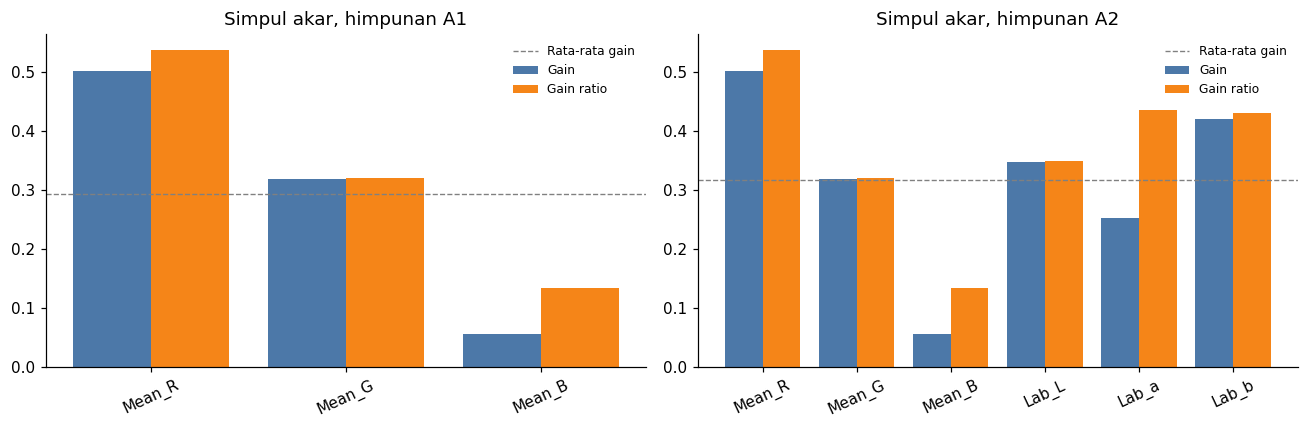

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, (table, average_gain, chosen)) in zip(axes, root_tables.items()):
    positions = np.arange(len(table))
    ax.bar(positions - 0.2, table["gain"], 0.4, label="Gain", color="#4C78A8")
    ax.bar(positions + 0.2, table["gain_ratio"], 0.4, label="Gain ratio", color="#F58518")
    ax.axhline(average_gain, color="grey", linestyle="--", linewidth=0.9, label="Rata-rata gain")
    ax.set_xticks(positions, table.index, rotation=25)
    ax.set_title(f"Simpul akar, himpunan {name}")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "03_root_gain_ratio.png")
plt.show()

##### 4.3 Rincian perhitungan pada pemisahan terpilih

In [10]:
features = FEATURE_SETS["A2"]
_, _, chosen = root_tables["A2"]
X_all = train[features].to_numpy(dtype=float)
left_mask = X_all[:, chosen["feature"]] <= chosen["threshold"]


def counts_row(mask):
    counts = np.bincount(y_index[mask], minlength=len(CLASSES)).astype(float)
    weighted = np.bincount(y_index[mask], weights=balanced_weights[mask], minlength=len(CLASSES))
    return counts, weighted


worked = []
for name, mask in (("S (akar)", np.ones(len(y_index), dtype=bool)), (f"S kiri ({features[chosen['feature']]} <= {chosen['threshold']:.3f})", left_mask), ("S kanan", ~left_mask)):
    counts, weighted = counts_row(mask)
    worked.append(
        {
            "himpunan": name,
            **{f"n_{c}": int(counts[i]) for i, c in enumerate(CLASSES)},
            "n": int(counts.sum()),
            "bobot_total": round(float(weighted.sum()), 3),
            "entropi": round(c45.entropy_from_counts(weighted), 4),
        }
    )
worked = pd.DataFrame(worked).set_index("himpunan")
display(worked)
print("Gain       :", round(chosen["gain"], 4))
print("SplitInfo  :", round(chosen["split_info"], 4))
print("Gain ratio :", round(chosen["gain_ratio"], 4))
worked.to_csv(TABLES_DIR / "03_root_worked_example.csv")

,n_normal,n_n_deficiency,n_fe_deficiency,n,bobot_total,entropi
himpunan,,,,,,
S (akar),92,70,142,304,304.000,1.5850
S kiri (Mean_R <= 144.550),91,9,118,218,197.467,1.2797
S kanan,1,61,24,86,106.533,0.7165


Gain       : 0.5026
SplitInfo  : 0.9345
Gain ratio : 0.5379


#### 5. Verifikasi Implementasi

##### 5.1 Perhitungan manual pada data kecil

In [11]:
toy_X = np.array([[1.0], [2.0], [3.0], [4.0], [5.0], [6.0]])
toy_y = np.array([0, 0, 0, 1, 1, 1])
toy = c45.split_candidates(toy_X, toy_y, np.ones(6), 2)[0]

checks = {
    "ambang = 3,5": abs(toy["threshold"] - 3.5) < 1e-9,
    "gain = 1": abs(toy["gain"] - 1.0) < 1e-9,
    "split info = 1": abs(toy["split_info"] - 1.0) < 1e-9,
    "entropi [3, 3] = 1": abs(c45.entropy_from_counts(np.array([3.0, 3.0])) - 1.0) < 1e-9,
    "entropi [6, 0] = 0": abs(c45.entropy_from_counts(np.array([6.0, 0.0]))) < 1e-9,
    "galat tambahan N=6, E=0, CF=0,25": abs(c45.add_errors(6, 0, 0.25) - 6 * (1 - 0.25 ** (1 / 6))) < 1e-9,
}
for name, passed in checks.items():
    print(("LULUS  " if passed else "GAGAL  ") + name)
assert all(checks.values())

LULUS  ambang = 3,5
LULUS  gain = 1
LULUS  split info = 1
LULUS  entropi [3, 3] = 1
LULUS  entropi [6, 0] = 0
LULUS  galat tambahan N=6, E=0, CF=0,25


##### 5.2 Perbandingan dengan pohon entropi scikit-learn

In [12]:
features = FEATURE_SETS["A2"]
X_train = train[features].to_numpy(dtype=float)
y_train = train["label"].to_numpy()

rows = []
for repeat, column in enumerate(ev.FOLD_COLUMNS, start=1):
    for fold, train_idx, val_idx in ev.iter_folds(train, column):
        own = c45.C45Classifier(class_weight=CLASS_WEIGHT).fit(X_train[train_idx], y_train[train_idx], features, CLASSES)
        reference = DecisionTreeClassifier(criterion="entropy", class_weight="balanced", random_state=SEED).fit(X_train[train_idx], y_train[train_idx])
        own_pred = own.predict(X_train[val_idx])
        reference_pred = reference.predict(X_train[val_idx])
        rows.append(
            {
                "repeat": repeat,
                "fold": fold,
                "own_macro_f1": ev.macro_f1(y_train[val_idx], own_pred),
                "sklearn_macro_f1": ev.macro_f1(y_train[val_idx], reference_pred),
                "own_leaves": own.n_leaves,
                "sklearn_leaves": reference.get_n_leaves(),
                "prediction_agreement": float(np.mean(own_pred == reference_pred)),
            }
        )
crosscheck = pd.DataFrame(rows)
crosscheck_summary = crosscheck.drop(columns=["repeat", "fold"]).agg(["mean", "std"]).T.round(4)
crosscheck_summary.to_csv(TABLES_DIR / "03_sklearn_crosscheck.csv")
display(crosscheck_summary)

,mean,std
own_macro_f1,0.6762,0.0983
sklearn_macro_f1,0.6902,0.0809
own_leaves,47.8667,6.8855
sklearn_leaves,51.1333,7.9090
prediction_agreement,0.8483,0.0688


##### 5.3 Kesesuaian prediksi model dan berkas JSON

In [13]:
check_model = c45.C45Classifier(class_weight=CLASS_WEIGHT, confidence_factor=0.25).fit(X_train, y_train, features, CLASSES)
check_payload = json.loads(json.dumps(check_model.to_dict(version="check")))

from_model = check_model.predict(X_train)
from_json = np.array([c45.predict_from_dict(check_payload, dict(zip(features, row)))["predicted_class"] for row in X_train])

print("Prediksi sama pada seluruh data latih :", bool((from_model == from_json).all()))
assert (from_model == from_json).all()

Prediksi sama pada seluruh data latih : True


#### 6. Penalaan Hiperparameter

##### 6.1 Ruang pencarian

In [14]:
grid = ev.c45_grid()
grid_summary = (
    grid.assign(depth=grid["max_depth"].map(ev.depth_label))
    .groupby("variant", sort=False)
    .agg(konfigurasi=("variant", "size"), kedalaman=("depth", lambda s: ", ".join(sorted(set(s)))), min_daun=("min_samples_leaf", lambda s: ", ".join(map(str, sorted(set(s))))), cf=("confidence_factor", lambda s: ", ".join(map(str, sorted(set(s.dropna()))) or ["-"])))
)
grid_summary.index = grid_summary.index.map({"unpruned": "Tanpa pemangkasan", "pre": "Pra-pemangkasan", "post": "Pasca-pemangkasan", "both": "Pra + pasca"})
grid_summary.loc["Total"] = [len(grid), "", "", ""]
display(grid_summary)
grid_summary.to_csv(TABLES_DIR / "03_grid_definition.csv")

,konfigurasi,kedalaman,min_daun,cf
variant,,,,
Tanpa pemangkasan,1,tak terbatas,1,
Pra-pemangkasan,15,"3, 4, 5, 6, tak terbatas","2, 5, 10",
Pasca-pemangkasan,4,tak terbatas,1,"0.05, 0.1, 0.25, 0.4"
Pra + pasca,60,"3, 4, 5, 6, tak terbatas","2, 5, 10","0.05, 0.1, 0.25, 0.4"
Total,80,,,


##### 6.2 Validasi silang berkelompok 5 lipatan × 3 pengulangan

In [15]:
tuning_scores, tuning_seconds, summaries = {}, {}, {}
for name, features in FEATURE_SETS.items():
    started = time.perf_counter()
    tuning_scores[name] = ev.tune_c45(train, features, grid, class_weight=CLASS_WEIGHT)
    tuning_seconds[name] = time.perf_counter() - started
    summaries[name] = ev.summarize_grid(grid, tuning_scores[name])
    summaries[name].to_csv(TABLES_DIR / f"03_tuning_summary_{name}.csv")
    print(f"{name}: {len(grid)} konfigurasi x {tuning_scores[name].groupby('config_id').size().iloc[0]} lipatan, {tuning_seconds[name]:.1f} detik")

A1: 80 konfigurasi x 15 lipatan, 12.8 detik
A2: 80 konfigurasi x 15 lipatan, 7.5 detik


##### 6.3 Konfigurasi terbaik tiap varian

In [16]:
VARIANT_NAME_ID = {"unpruned": "Tanpa pemangkasan", "pre": "Pra-pemangkasan", "post": "Pasca-pemangkasan", "both": "Pra + pasca"}
VARIANT_ORDER = list(VARIANT_NAME_ID)

best_per_variant = {}
rows = []
for name, summary in summaries.items():
    for variant in VARIANT_ORDER:
        best = ev.select_best_config(summary[summary["variant"] == variant])
        best_per_variant[(name, variant)] = best
        rows.append(
            {
                "himpunan": name,
                "varian": VARIANT_NAME_ID[variant],
                "kedalaman": ev.depth_label(best["max_depth"]),
                "min_daun": int(best["min_samples_leaf"]),
                "CF": best["confidence_factor"],
                "F1 makro latih": best["train_f1_mean"],
                "F1 makro validasi": best["val_f1_mean"],
                "SD validasi": best["val_f1_sd"],
                "akurasi validasi": best["val_acc_mean"],
                "daun (rata-rata)": best["leaves_mean"],
                "kedalaman pohon (rata-rata)": best["depth_mean"],
            }
        )
variant_table = pd.DataFrame(rows).set_index(["himpunan", "varian"])
variant_table.round(4).to_csv(TABLES_DIR / "03_variant_comparison.csv")
display(variant_table.round(4))

kedalaman  min_daun    CF  F1 makro latih  \
himpunan varian                                                            
A1       Tanpa pemangkasan  tak terbatas         1   NaN          1.0000   
         Pra-pemangkasan               3        10   NaN          0.7465   
         Pasca-pemangkasan  tak terbatas         1  0.25          0.9442   
         Pra + pasca                   3        10  0.40          0.7495   
A2       Tanpa pemangkasan  tak terbatas         1   NaN          1.0000   
         Pra-pemangkasan               6         2   NaN          0.8907   
         Pasca-pemangkasan  tak terbatas         1  0.10          0.9329   
         Pra + pasca                   5         2  0.05          0.8491   

                            F1 makro validasi  SD validasi  akurasi validasi  \
himpunan varian                                                                
A1       Tanpa pemangkasan             0.6731       0.0830            0.6729   
         Pra-pemangkasan               0.6890       0.0790            0.6920   
         Pasca-pemangkasan             0.6829       0.0828            0.6813   
         Pra + pasca                   0.6988       0.0804            0.7006   
A2       Tanpa pemangkasan             0.6762       0.0983            0.6749   
         Pra-pemangkasan               0.7138       0.1019            0.7159   
         Pasca-pemangkasan             0.7097       0.0985            0.7105   
         Pra + pasca                   0.7307       0.1118            0.7302   

                            daun (rata-rata)  kedalaman pohon (rata-rata)  
himpunan varian                                                            
A1       Tanpa pemangkasan           58.6667                      14.6000  
         Pra-pemangkasan              7.0000                       3.0000  
         Pasca-pemangkasan           35.2000                      12.2000  
         Pra + pasca                  5.1333                       2.9333  
A2       Tanpa pemangkasan           47.8667                      13.3333  
         Pra-pemangkasan             23.0667                       6.0000  
         Pasca-pemangkasan           25.0667                      10.0000  
         Pra + pasca                 12.0000                       4.9333

##### 6.4 Peta panas F1 makro validasi

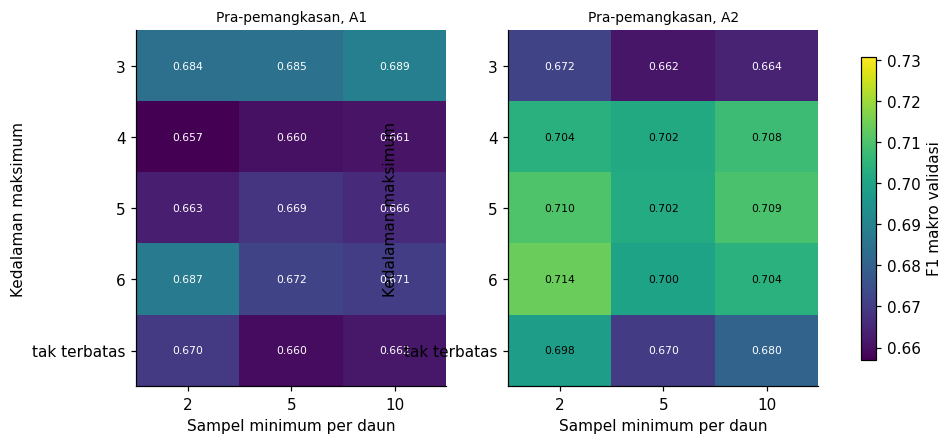

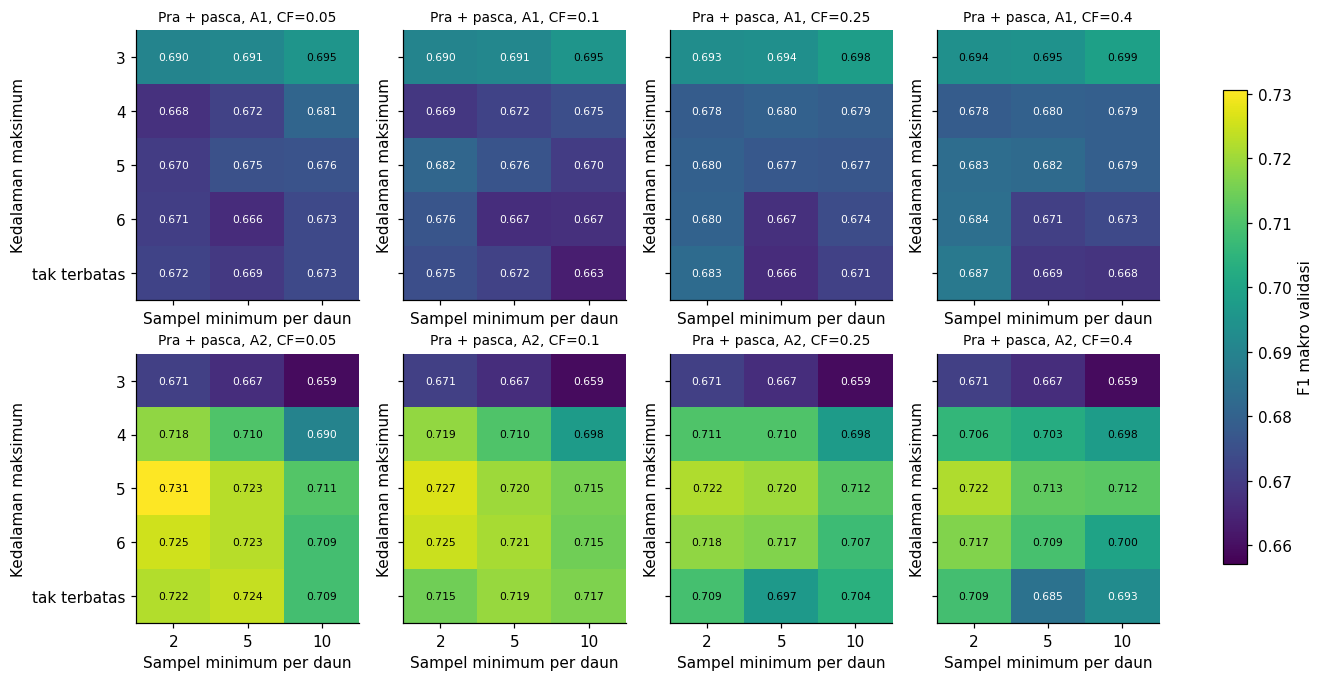

In [17]:
all_f1 = pd.concat([s["val_f1_mean"] for s in summaries.values()])
vmin, vmax = float(all_f1.min()), float(all_f1.max())
depth_order = [d for d in ev.PRE_DEPTHS]
leaf_order = list(ev.PRE_LEAVES)


def pivot_for(summary, variant, cf=None):
    subset = summary[summary["variant"] == variant]
    if cf is not None:
        subset = subset[subset["confidence_factor"].round(4) == cf]
    subset = subset.assign(depth_label=subset["max_depth"].map(ev.depth_label))
    table = subset.pivot(index="depth_label", columns="min_samples_leaf", values="val_f1_mean")
    return table.reindex([ev.depth_label(d) for d in depth_order])[leaf_order]


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, summary) in zip(axes, summaries.items()):
    image = ev.plot_heatmap(ax, pivot_for(summary, "pre"), f"Pra-pemangkasan, {name}", vmin, vmax, "Sampel minimum per daun", "Kedalaman maksimum")
fig.colorbar(image, ax=axes, shrink=0.85, label="F1 makro validasi")
save_figure(fig, "03_heatmap_pre_pruning.png")
plt.show()

fig, axes = plt.subplots(2, len(ev.CONFIDENCE_FACTORS), figsize=(15, 7), sharex=True, sharey=True)
for row, (name, summary) in enumerate(summaries.items()):
    for col, cf in enumerate(ev.CONFIDENCE_FACTORS):
        image = ev.plot_heatmap(axes[row, col], pivot_for(summary, "both", cf), f"Pra + pasca, {name}, CF={cf}", vmin, vmax, "Sampel minimum per daun", "Kedalaman maksimum")
fig.colorbar(image, ax=axes, shrink=0.8, label="F1 makro validasi")
save_figure(fig, "03_heatmap_both.png")
plt.show()

##### 6.5 Kurva pemangkasan terhadap confidence factor

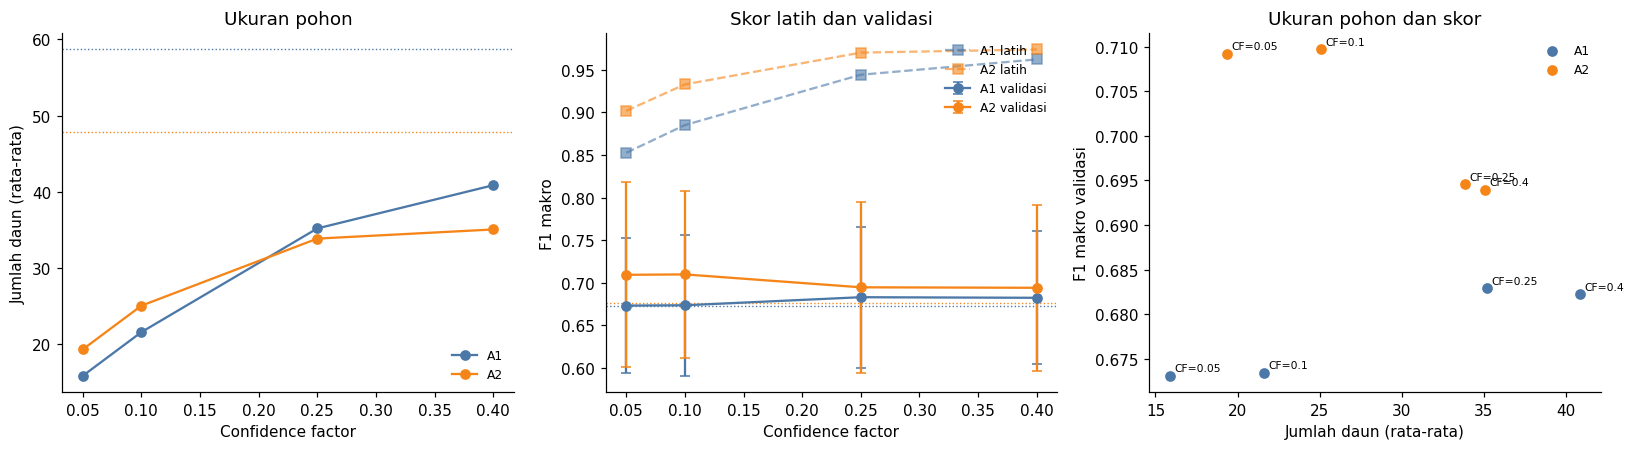

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
palette = {"A1": "#4C78A8", "A2": "#F58518"}
for name, summary in summaries.items():
    post = summary[summary["variant"] == "post"].sort_values("confidence_factor")
    unpruned = summary[summary["variant"] == "unpruned"].iloc[0]
    axes[0].plot(post["confidence_factor"], post["leaves_mean"], marker="o", color=palette[name], label=name)
    axes[0].axhline(unpruned["leaves_mean"], color=palette[name], linestyle=":", linewidth=0.9)
    axes[1].errorbar(post["confidence_factor"], post["val_f1_mean"], yerr=post["val_f1_sd"], marker="o", capsize=3, color=palette[name], label=f"{name} validasi")
    axes[1].plot(post["confidence_factor"], post["train_f1_mean"], marker="s", linestyle="--", color=palette[name], alpha=0.6, label=f"{name} latih")
    axes[1].axhline(unpruned["val_f1_mean"], color=palette[name], linestyle=":", linewidth=0.9)
    axes[2].scatter(post["leaves_mean"], post["val_f1_mean"], color=palette[name], label=name)
    for _, r in post.iterrows():
        axes[2].annotate(f"CF={r['confidence_factor']}", (r["leaves_mean"], r["val_f1_mean"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].set(xlabel="Confidence factor", ylabel="Jumlah daun (rata-rata)", title="Ukuran pohon")
axes[1].set(xlabel="Confidence factor", ylabel="F1 makro", title="Skor latih dan validasi")
axes[2].set(xlabel="Jumlah daun (rata-rata)", ylabel="F1 makro validasi", title="Ukuran pohon dan skor")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_figure(fig, "03_pruning_curve.png")
plt.show()

##### 6.6 Sebaran skor lipatan tiap varian

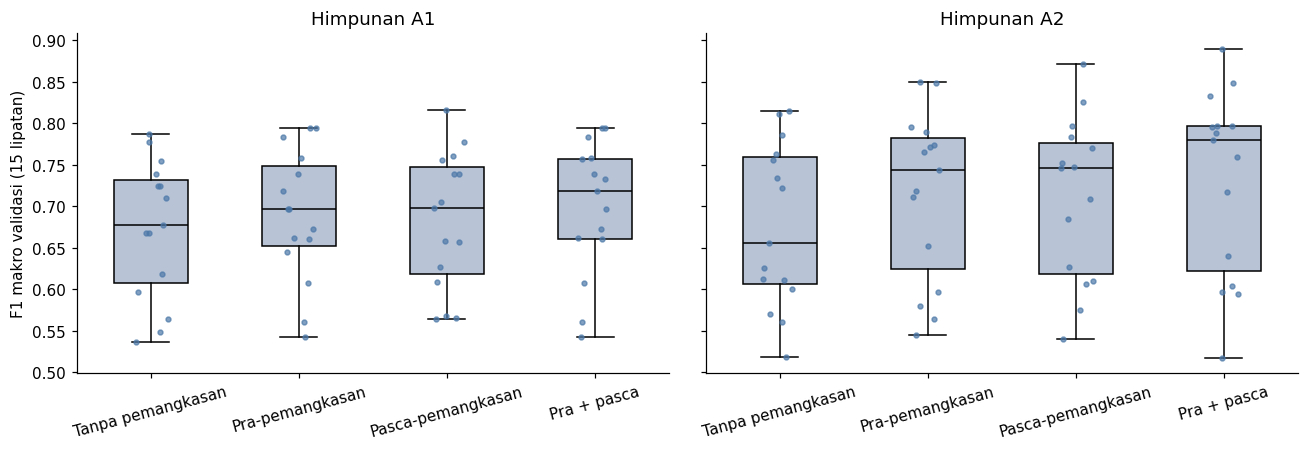

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, name in zip(axes, FEATURE_SETS):
    data, labels = [], []
    for variant in VARIANT_ORDER:
        config_id = int(best_per_variant[(name, variant)].name)
        scores = tuning_scores[name]
        data.append(scores.loc[scores["config_id"] == config_id, "val_macro_f1"].to_numpy())
        labels.append(VARIANT_NAME_ID[variant])
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    for i, values in enumerate(data, start=1):
        ax.scatter(np.full(len(values), i) + rng.uniform(-0.12, 0.12, len(values)), values, s=10, color="#4C78A8", alpha=0.7, zorder=3)
    ax.set_xticks(range(1, len(labels) + 1), labels, rotation=15)
    ax.set_title(f"Himpunan {name}")
axes[0].set_ylabel("F1 makro validasi (15 lipatan)")
fig.tight_layout()
save_figure(fig, "03_variant_boxplot.png")
plt.show()

##### 6.7 Peringkat konfigurasi

In [20]:
for name, summary in summaries.items():
    ranked = summary.assign(varian=summary["variant"].map(VARIANT_NAME_ID), kedalaman=summary["max_depth"].map(ev.depth_label))
    ranked = ranked.assign(_f1=ranked["val_f1_mean"].round(4)).sort_values(["_f1", "leaves_mean"], ascending=[False, True], kind="stable")
    top = ranked[["varian", "kedalaman", "min_samples_leaf", "confidence_factor", "val_f1_mean", "val_f1_sd", "leaves_mean"]].head(10)
    top.round(4).to_csv(TABLES_DIR / f"03_top_configs_{name}.csv")
    print(f"Sepuluh konfigurasi terbaik, himpunan {name}")
    display(top.round(4))

Sepuluh konfigurasi terbaik, himpunan A1


,varian,kedalaman,min_samples_leaf,confidence_factor,val_f1_mean,val_f1_sd,leaves_mean
31,Pra + pasca,3,10,0.40,0.6988,0.0804,5.1333
30,Pra + pasca,3,10,0.25,0.6981,0.0796,5.0667
28,Pra + pasca,3,10,0.05,0.6954,0.0767,5.0000
29,Pra + pasca,3,10,0.10,0.6954,0.0767,5.0000
27,Pra + pasca,3,5,0.40,0.6946,0.0766,5.1333
23,Pra + pasca,3,2,0.40,0.6940,0.0742,5.3333
26,Pra + pasca,3,5,0.25,0.6938,0.0762,5.0667
22,Pra + pasca,3,2,0.25,0.6931,0.0738,5.2667
24,Pra + pasca,3,5,0.05,0.6911,0.0731,5.0000
25,Pra + pasca,3,5,0.10,0.6911,0.0731,5.0000


Sepuluh konfigurasi terbaik, himpunan A2


,varian,kedalaman,min_samples_leaf,confidence_factor,val_f1_mean,val_f1_sd,leaves_mean
44,Pra + pasca,5,2,0.05,0.7307,0.1118,12.0000
45,Pra + pasca,5,2,0.10,0.7265,0.1083,12.3333
56,Pra + pasca,6,2,0.05,0.7253,0.1005,14.0667
57,Pra + pasca,6,2,0.10,0.7248,0.0989,14.8667
72,Pra + pasca,tak terbatas,5,0.05,0.7244,0.1118,10.8667
60,Pra + pasca,6,5,0.05,0.7229,0.1142,10.6000
48,Pra + pasca,5,5,0.05,0.7228,0.1240,9.6000
68,Pra + pasca,tak terbatas,2,0.05,0.7223,0.0995,15.7333
46,Pra + pasca,5,2,0.25,0.7220,0.1112,13.2000
47,Pra + pasca,5,2,0.40,0.7220,0.1112,13.2000


##### 6.8 Pemilihan konfigurasi dan himpunan fitur

Aturan yang ditetapkan sebelum pelatihan: konfigurasi dengan rata-rata F1 makro validasi tertinggi dipilih, dan jika sama pada empat desimal dipilih pohon dengan daun lebih sedikit. Himpunan A2 menggantikan A1 hanya jika

$$
\overline{F1}_{A2} - \overline{F1}_{A1} > s_{A1}
$$

dengan $s_{A1}$ simpangan baku F1 makro A1 pada 15 lipatan.

In [21]:
best_config = {name: ev.select_best_config(summary) for name, summary in summaries.items()}
a1, a2 = best_config["A1"], best_config["A2"]
difference = float(a2["val_f1_mean"] - a1["val_f1_mean"])
SELECTED_SET = "A2" if difference > float(a1["val_f1_sd"]) else "A1"

decision_table = pd.DataFrame(
    {
        "A1": {"varian": VARIANT_NAME_ID[a1["variant"]], "F1 makro validasi": a1["val_f1_mean"], "SD": a1["val_f1_sd"], "daun": a1["leaves_mean"]},
        "A2": {"varian": VARIANT_NAME_ID[a2["variant"]], "F1 makro validasi": a2["val_f1_mean"], "SD": a2["val_f1_sd"], "daun": a2["leaves_mean"]},
    }
)
display(decision_table)
print(f"Selisih F1 makro (A2 - A1) : {difference:.4f}")
print(f"SD F1 makro A1             : {float(a1['val_f1_sd']):.4f}")
print(f"Himpunan fitur terpilih    : {SELECTED_SET}")

SELECTED_FEATURES = FEATURE_SETS[SELECTED_SET]
SELECTED_PARAMS = ev.params_of(best_config[SELECTED_SET])
print("Parameter terpilih         :", SELECTED_PARAMS)
decision_table.to_csv(TABLES_DIR / "03_feature_set_decision.csv")

,A1,A2
varian,Pra + pasca,Pra + pasca
F1 makro validasi,0.6988,0.730682
SD,0.080413,0.111838
daun,5.133333,12.0


Selisih F1 makro (A2 - A1) : 0.0319
SD F1 makro A1             : 0.0804
Himpunan fitur terpilih    : A1
Parameter terpilih         : {'max_depth': 3, 'min_samples_leaf': 10, 'confidence_factor': 0.4}


#### 7. Evaluasi Validasi Silang Model Terpilih

##### 7.1 Prediksi out-of-fold

In [22]:
def make_c45(params):
    return lambda: c45.C45Classifier(class_weight=CLASS_WEIGHT, **params)


oof = {}
for name in FEATURE_SETS:
    oof[name] = ev.cross_val_predictions(make_c45(ev.params_of(best_config[name])), train, FEATURE_SETS[name])
    oof[name].to_csv(RESULTS_DIR / f"03_c45_oof_{name}.csv", index=False)

oof_selected = oof[SELECTED_SET]
print("Himpunan fitur :", SELECTED_SET)
print("Baris OOF      :", len(oof_selected), f"({oof_selected['repeat'].nunique()} pengulangan)")

Himpunan fitur : A1
Baris OOF      : 912 (3 pengulangan)


##### 7.2 Matriks konfusi

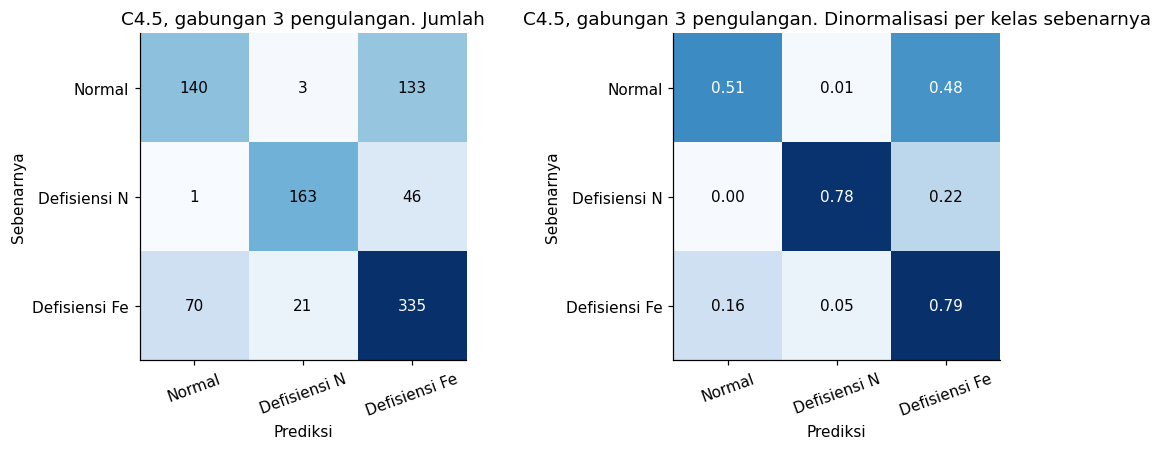

,Normal -> Defisiensi N,Normal -> Defisiensi F,Defisiensi N -> Normal,Defisiensi N -> Defisiensi F,Defisiensi F -> Normal,Defisiensi F -> Defisiensi N
pengulangan,,,,,,
1,0,42,0,15,21,8
2,2,46,1,13,31,3
3,1,45,0,18,18,10


In [23]:
pooled_counts = ev.confusion_counts(oof_selected["label"], oof_selected["pred"])
axes = ev.plot_confusion(pooled_counts, title="C4.5, gabungan 3 pengulangan.")
plt.gcf().tight_layout()
save_figure(plt.gcf(), "03_confusion_matrix.png")
plt.show()

per_repeat = pd.DataFrame(
    [
        {"pengulangan": r, **{f"{CLASS_LABEL_ID[t][:12]} -> {CLASS_LABEL_ID[p][:12]}": int(((part['label'] == t) & (part['pred'] == p)).sum()) for t in CLASSES for p in CLASSES if t != p}}
        for r, part in oof_selected.groupby("repeat")
    ]
).set_index("pengulangan")
per_repeat.to_csv(TABLES_DIR / "03_confusion_errors_per_repeat.csv")
display(per_repeat)

##### 7.3 Metrik per kelas

In [24]:
metric_table = ev.metrics_table(oof_selected["label"], oof_selected["pred"])
metric_table.round(4).to_csv(TABLES_DIR / "03_classification_metrics.csv")
display(metric_table.round(4))

fold_table = ev.fold_scores(oof_selected)
fold_summary = fold_table[["macro_f1", "accuracy"]].agg(["mean", "std", "min", "max"]).T.round(4)
fold_summary.to_csv(TABLES_DIR / "03_fold_summary.csv")
display(fold_summary)

,precision,recall,f1,support
Normal,0.6635,0.5072,0.5749,276.0
Defisiensi N,0.8717,0.7762,0.8212,210.0
Defisiensi Fe,0.6518,0.7864,0.7128,426.0
Rata-rata makro,0.7290,0.6899,0.7030,912.0
Rata-rata berbobot,0.7059,0.6996,0.6960,912.0
Akurasi,NaN,NaN,0.6996,912.0


,mean,std,min,max
macro_f1,0.6988,0.0804,0.5432,0.7949
accuracy,0.7006,0.0725,0.5833,0.7910


##### 7.4 Skor per lipatan

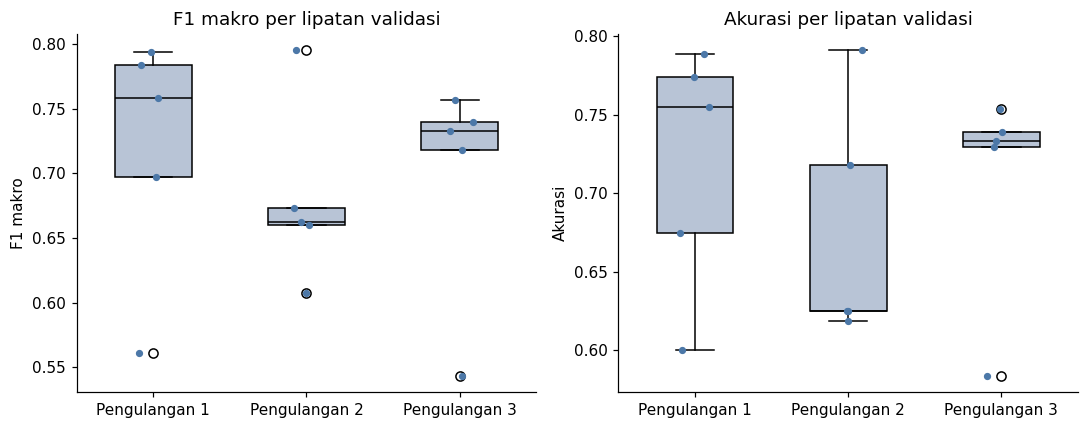

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(axes, ("macro_f1", "accuracy"), ("F1 makro", "Akurasi")):
    data = [fold_table.loc[fold_table["repeat"] == r, metric].to_numpy() for r in sorted(fold_table["repeat"].unique())]
    boxes = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": "black"})
    for patch in boxes["boxes"]:
        patch.set_facecolor("#B8C4D6")
    for i, values in enumerate(data, start=1):
        ax.scatter(np.full(len(values), i) + rng.uniform(-0.1, 0.1, len(values)), values, s=14, color="#4C78A8", zorder=3)
    ax.set_xticks(range(1, len(data) + 1), [f"Pengulangan {r}" for r in sorted(fold_table["repeat"].unique())])
    ax.set_ylabel(title)
    ax.set_title(f"{title} per lipatan validasi")
fig.tight_layout()
save_figure(fig, "03_fold_scores.png")
plt.show()

##### 7.5 Kurva ROC dan Precision-Recall

$$
\mathrm{TPR} = \frac{TP}{TP + FN}, \qquad \mathrm{FPR} = \frac{FP}{FP + TN}, \qquad \mathrm{AP} = \sum_{n} (R_n - R_{n-1})\, P_n
$$

Skor setiap kelas adalah proporsi sampel latih kelas tersebut pada daun yang dicapai.

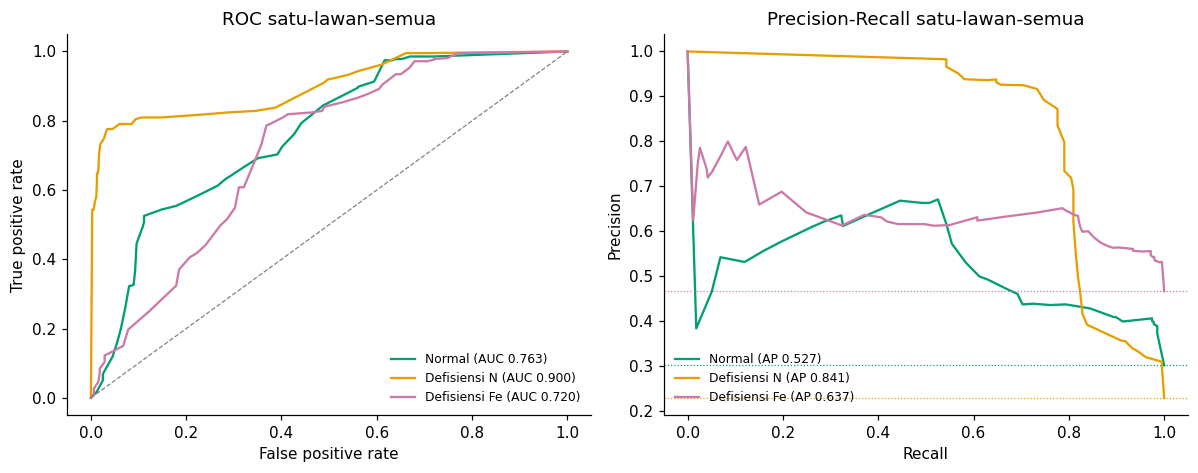

,AUC,AP,prevalensi
Normal,0.7633,0.5274,0.3026
Defisiensi N,0.8998,0.8413,0.2303
Defisiensi Fe,0.7197,0.6367,0.4671
Rata-rata makro,0.7943,0.6685,0.3333


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
curves = ev.plot_roc_pr(oof_selected, axes)
fig.tight_layout()
save_figure(fig, "03_roc_pr.png")
plt.show()

curve_table = pd.DataFrame({CLASS_LABEL_ID[c]: {"AUC": curves[c]["auc"], "AP": curves[c]["ap"], "prevalensi": curves[c]["prevalence"]} for c in CLASSES}).T
curve_table.loc["Rata-rata makro"] = curve_table.mean()
curve_table.round(4).to_csv(TABLES_DIR / "03_roc_pr_summary.csv")
display(curve_table.round(4))

##### 7.6 Kurva pembelajaran

,train_files,train_f1,train_sd,val_f1,val_sd
fraction,,,,,
0.2,61.0,0.7504,0.0904,0.5856,0.0965
0.4,108.4,0.7174,0.0590,0.6071,0.1682
0.6,153.6,0.7194,0.0270,0.6696,0.0941
0.8,197.8,0.7425,0.0364,0.7022,0.0791
1.0,243.2,0.7521,0.0311,0.7187,0.0959


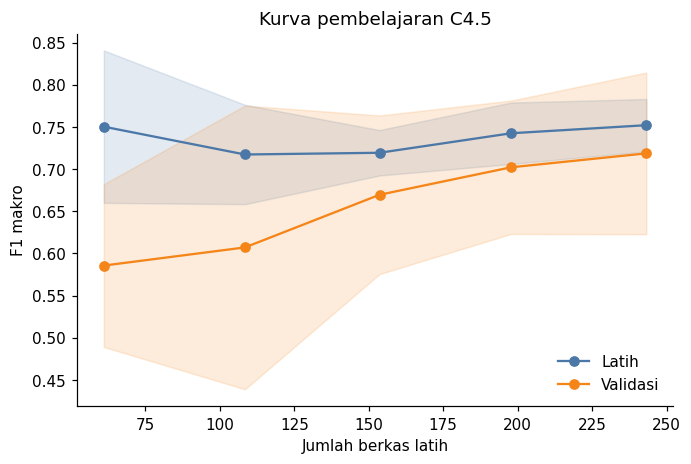

In [27]:
learning = ev.learning_curve(make_c45(SELECTED_PARAMS), train, SELECTED_FEATURES, fractions=LEARNING_FRACTIONS, seed=SEED)
learning_summary = learning.groupby("fraction").agg(
    train_files=("train_files", "mean"),
    train_f1=("train_macro_f1", "mean"), train_sd=("train_macro_f1", "std"),
    val_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
)
learning_summary.round(4).to_csv(TABLES_DIR / "03_learning_curve.csv")
display(learning_summary.round(4))

fig, ax = plt.subplots(figsize=(7, 4.4))
for column, sd, label, color in (("train_f1", "train_sd", "Latih", "#4C78A8"), ("val_f1", "val_sd", "Validasi", "#F58518")):
    ax.plot(learning_summary["train_files"], learning_summary[column], marker="o", color=color, label=label)
    ax.fill_between(learning_summary["train_files"], learning_summary[column] - learning_summary[sd], learning_summary[column] + learning_summary[sd], color=color, alpha=0.15)
ax.set(xlabel="Jumlah berkas latih", ylabel="F1 makro", title="Kurva pembelajaran C4.5")
ax.legend(frameon=False)
save_figure(fig, "03_learning_curve.png")
plt.show()

##### 7.7 Pentingnya fitur (permutasi)

$$
\mathrm{PI}_j = F1_{\text{dasar}} - \frac{1}{R}\sum_{r=1}^{R} F1_{\text{acak}}^{(j, r)}
$$

,importance_mean,importance_sd
feature,,
Mean_R,0.3880,0.1055
Mean_G,0.0193,0.0431
Mean_B,0.0349,0.0322


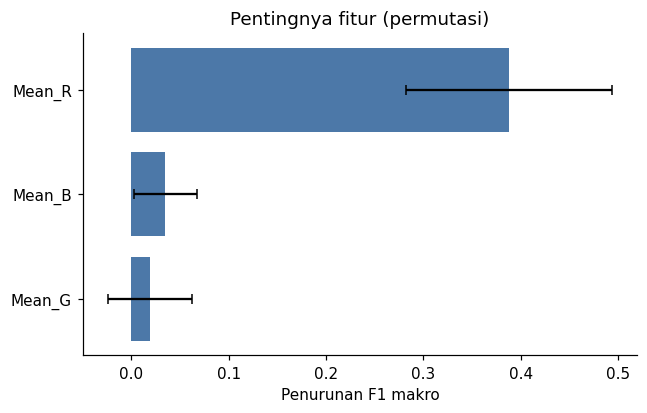

In [28]:
importance = ev.permutation_importance(make_c45(SELECTED_PARAMS), train, SELECTED_FEATURES, n_repeats=PERMUTATION_REPEATS, seed=SEED)
importance.round(4).to_csv(TABLES_DIR / "03_permutation_importance.csv")
display(importance.round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ordered = importance.sort_values("importance_mean")
ax.barh(ordered.index, ordered["importance_mean"], xerr=ordered["importance_sd"], color="#4C78A8", capsize=3)
ax.set(xlabel="Penurunan F1 makro", title="Pentingnya fitur (permutasi)")
save_figure(fig, "03_permutation_importance.png")
plt.show()

##### 7.8 Kepercayaan daun dan ketepatan prediksi

,jumlah,akurasi
confidence_bin,,
"[0.0, 0.6)",38,0.6053
"[0.6, 0.8)",648,0.6481
"[0.8, 0.95)",110,0.7364
"[0.95, 1.0)",116,0.9828


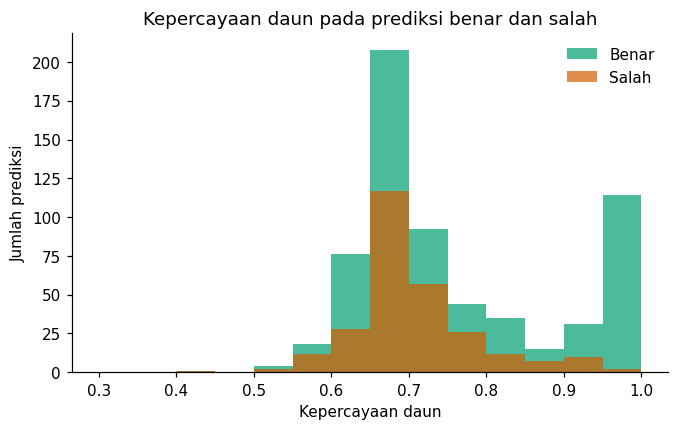

In [29]:
oof_selected = oof_selected.assign(correct=oof_selected["label"] == oof_selected["pred"])
oof_selected["confidence_bin"] = pd.cut(oof_selected["confidence"], bins=CONFIDENCE_BINS, right=False)
confidence_table = oof_selected.groupby("confidence_bin", observed=True).agg(jumlah=("correct", "size"), akurasi=("correct", "mean"))
confidence_table.round(4).to_csv(TABLES_DIR / "03_confidence_bins.csv")
display(confidence_table.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0.3, 1.0, 15)
ax.hist(oof_selected.loc[oof_selected["correct"], "confidence"], bins=bins, alpha=0.7, color="#009E73", label="Benar")
ax.hist(oof_selected.loc[~oof_selected["correct"], "confidence"], bins=bins, alpha=0.7, color="#D55E00", label="Salah")
ax.set(xlabel="Kepercayaan daun", ylabel="Jumlah prediksi", title="Kepercayaan daun pada prediksi benar dan salah")
ax.legend(frameon=False)
save_figure(fig, "03_confidence_histogram.png")
plt.show()

##### 7.9 Galeri salah klasifikasi

,label,pred,jumlah
0,Defisiensi Fe,Defisiensi N,8
1,Defisiensi Fe,Normal,21
2,Defisiensi N,Defisiensi Fe,15
3,Normal,Defisiensi Fe,42


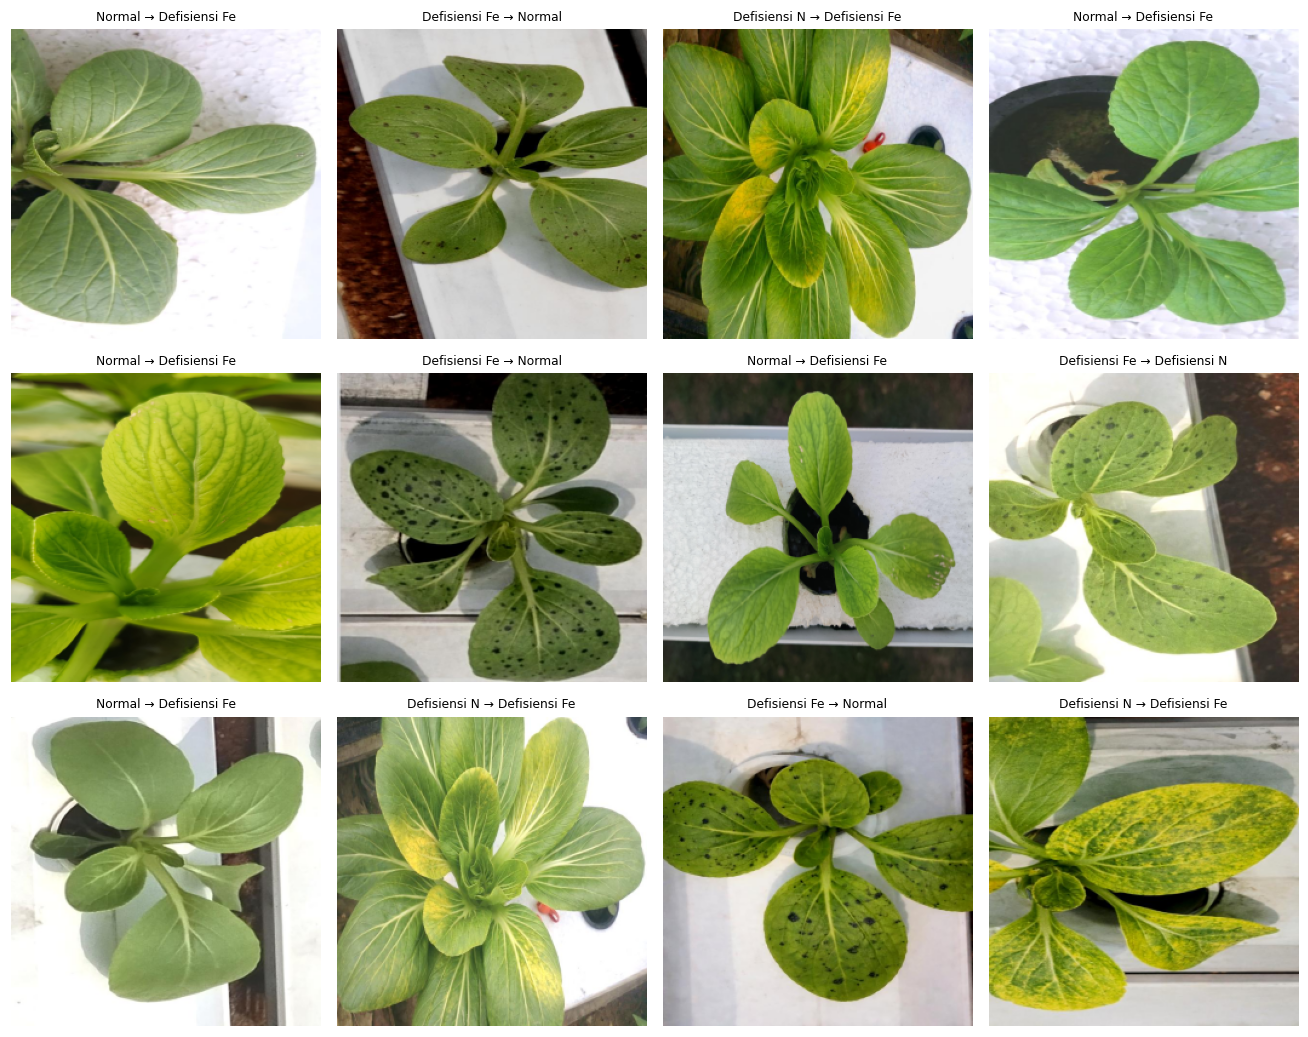

In [30]:
errors = oof_selected[(oof_selected["repeat"] == 1) & (~oof_selected["correct"])]
error_pairs = errors.groupby(["label", "pred"]).size().rename("jumlah").reset_index()
error_pairs["label"] = error_pairs["label"].map(CLASS_LABEL_ID)
error_pairs["pred"] = error_pairs["pred"].map(CLASS_LABEL_ID)
display(error_pairs)
error_pairs.to_csv(TABLES_DIR / "03_misclassified_pairs.csv", index=False)

fig = ev.plot_gallery(errors, RAW_DIR, max_items=GALLERY_SIZE, seed=SEED)
save_figure(fig, "03_misclassified_gallery.png")
plt.show()

##### 7.10 Interval kepercayaan bootstrap (resampling foto sumber)

$$
\hat{\theta}^{*(b)} = \theta\left(\{g_1^{*}, \dots, g_G^{*}\}\right), \qquad g_i^{*} \sim \mathrm{Uniform}(\mathcal{G}), \qquad \mathrm{CI}_{95\%} = \left[\hat{\theta}^{*}_{0{,}025},\ \hat{\theta}^{*}_{0{,}975}\right]
$$

,estimate,low,high
F1 makro,0.7030,0.6333,0.7592
Akurasi,0.6996,0.6338,0.7626
Recall Defisiensi N,0.7762,0.5903,0.9280
Recall Defisiensi Fe,0.7864,0.7303,0.8439
Recall Normal,0.5072,0.4023,0.6154


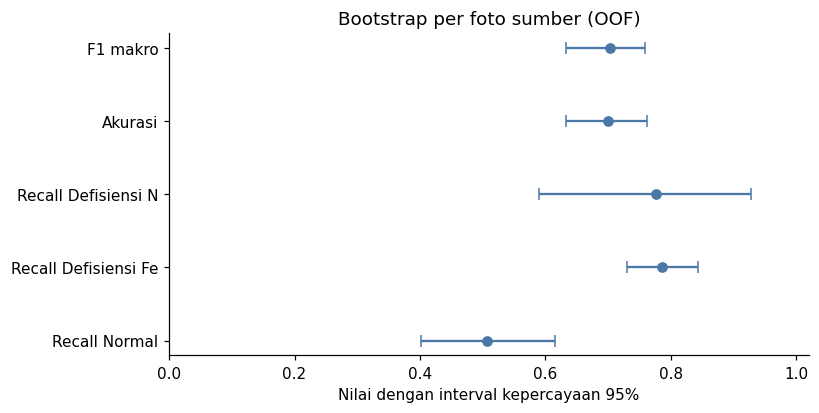

In [31]:
bootstrap_metrics = {
    "F1 makro": ev.fast_macro_f1,
    "Akurasi": ev.fast_accuracy,
    "Recall Defisiensi N": ev.fast_recall("n_deficiency"),
    "Recall Defisiensi Fe": ev.fast_recall("fe_deficiency"),
    "Recall Normal": ev.fast_recall("normal"),
}
bootstrap_rows = {name: ev.bootstrap_group_ci(oof_selected, metric, n_boot=N_BOOTSTRAP, seed=SEED) for name, metric in bootstrap_metrics.items()}
bootstrap_table = pd.DataFrame(bootstrap_rows).T[["estimate", "low", "high"]]
bootstrap_table.round(4).to_csv(TABLES_DIR / "03_bootstrap_ci.csv")
display(bootstrap_table.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y_positions = np.arange(len(bootstrap_table))[::-1]
ax.errorbar(bootstrap_table["estimate"], y_positions, xerr=[bootstrap_table["estimate"] - bootstrap_table["low"], bootstrap_table["high"] - bootstrap_table["estimate"]], fmt="o", color="#4C78A8", capsize=4)
ax.set_yticks(y_positions, bootstrap_table.index)
ax.set(xlabel="Nilai dengan interval kepercayaan 95%", title="Bootstrap per foto sumber (OOF)")
ax.set_xlim(0, 1.02)
save_figure(fig, "03_bootstrap_ci.png")
plt.show()

##### 7.11 Perbandingan himpunan fitur A1 dan A2

In [32]:
comparison_rows = {}
for name in FEATURE_SETS:
    part = oof[name]
    folds = ev.fold_scores(part)
    comparison_rows[name] = {
        "varian": VARIANT_NAME_ID[best_config[name]["variant"]],
        "F1 makro (rata-rata lipatan)": folds["macro_f1"].mean(),
        "SD lipatan": folds["macro_f1"].std(),
        "akurasi": folds["accuracy"].mean(),
        "recall Normal": ev.fast_recall("normal")(part["label"], part["pred"]),
        "recall Defisiensi N": ev.fast_recall("n_deficiency")(part["label"], part["pred"]),
        "recall Defisiensi Fe": ev.fast_recall("fe_deficiency")(part["label"], part["pred"]),
        "daun": best_config[name]["leaves_mean"],
    }
feature_set_comparison = pd.DataFrame(comparison_rows)
feature_set_comparison.to_csv(TABLES_DIR / "03_feature_set_comparison.csv")
display(feature_set_comparison)

,A1,A2
varian,Pra + pasca,Pra + pasca
F1 makro (rata-rata lipatan),0.6988,0.730682
SD lipatan,0.080413,0.111838
akurasi,0.700559,0.730244
recall Normal,0.507246,0.677536
recall Defisiensi N,0.77619,0.795238
recall Defisiensi Fe,0.786385,0.713615
daun,5.133333,12.0


##### 7.12 Sensitivitas pembobotan kelas

In [33]:
sensitivity_rows = {}
for weight in (None, "balanced"):
    part = ev.cross_val_predictions(lambda w=weight: c45.C45Classifier(class_weight=w, **SELECTED_PARAMS), train, SELECTED_FEATURES)
    folds = ev.fold_scores(part)
    sensitivity_rows[f"class_weight={weight}"] = {
        "F1 makro (rata-rata lipatan)": folds["macro_f1"].mean(),
        "SD lipatan": folds["macro_f1"].std(),
        "recall Defisiensi N": ev.fast_recall("n_deficiency")(part["label"], part["pred"]),
        "recall Defisiensi Fe": ev.fast_recall("fe_deficiency")(part["label"], part["pred"]),
    }
sensitivity = pd.DataFrame(sensitivity_rows).T
sensitivity.round(4).to_csv(TABLES_DIR / "03_class_weight_sensitivity.csv")
display(sensitivity.round(4))

,F1 makro (rata-rata lipatan),SD lipatan,recall Defisiensi N,recall Defisiensi Fe
class_weight=None,0.6968,0.0984,0.7619,0.7958
class_weight=balanced,0.6988,0.0804,0.7762,0.7864


#### 8. Pohon Akhir

##### 8.1 Pelatihan pada seluruh data latih

In [34]:
X_selected = train[SELECTED_FEATURES].to_numpy(dtype=float)
y_selected = train["label"].to_numpy()

final_model = c45.C45Classifier(class_weight=CLASS_WEIGHT, **SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES)
train_pred = final_model.predict(X_selected)

print("Parameter      :", SELECTED_PARAMS)
print("Jumlah daun    :", final_model.n_leaves)
print("Kedalaman      :", final_model.depth)
print("F1 makro latih :", round(ev.macro_f1(y_selected, train_pred), 4))
print("Akurasi latih  :", round(float(np.mean(train_pred == y_selected)), 4))

Parameter      : {'max_depth': 3, 'min_samples_leaf': 10, 'confidence_factor': 0.4}
Jumlah daun    : 5
Kedalaman      : 3
F1 makro latih : 0.7468
Akurasi latih  : 0.7434


##### 8.2 Diagram pohon

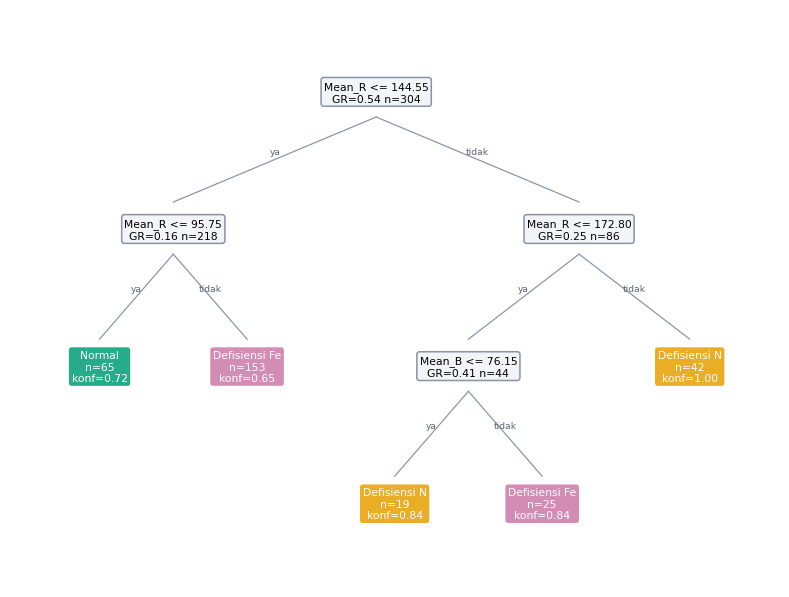

In [35]:
payload = final_model.to_dict(
    version="c45-candidate",
    extra={
        "feature_set": SELECTED_SET,
        "class_weight": CLASS_WEIGHT,
        "trained_rows": int(len(train)),
        "trained_groups": int(train["source_group"].nunique()),
        "seed": SEED,
        "created_at": datetime.now().isoformat(timespec="seconds"),
    },
)
ev.plot_tree_diagram(payload)
save_figure(plt.gcf(), "03_tree_diagram.png")
plt.show()

##### 8.3 Daftar aturan

In [36]:
def format_rule(conditions):
    if not conditions:
        return "(tanpa syarat)"
    return " DAN ".join(f"{feature} {operator} {threshold:.2f}" for feature, operator, threshold in conditions)


rules = final_model.rules()
rule_table = pd.DataFrame(
    [
        {
            "aturan": f"JIKA {format_rule(r['conditions'])}",
            "kelas": CLASS_LABEL_ID[r["class"]],
            "sampel": r["samples"],
            "konfidensi": round(r["confidence"], 4),
            **{f"n_{c}": r["distribution"][c] for c in CLASSES},
        }
        for r in rules
    ]
)
rule_table = rule_table.sort_values(["kelas", "sampel"], ascending=[True, False]).reset_index(drop=True)
rule_table.index = rule_table.index + 1
rule_table.index.name = "no"
rule_table.to_csv(TABLES_DIR / "03_rule_list.csv")
pd.set_option("display.max_colwidth", 200)
display(rule_table)

,aturan,kelas,sampel,konfidensi,n_normal,n_n_deficiency,n_fe_deficiency
no,,,,,,,
1,JIKA Mean_R <= 144.55 DAN Mean_R > 95.75,Defisiensi Fe,153,0.6536,44,9,100
2,JIKA Mean_R > 144.55 DAN Mean_R <= 172.80 DAN Mean_B > 76.15,Defisiensi Fe,25,0.8400,1,3,21
3,JIKA Mean_R > 144.55 DAN Mean_R > 172.80,Defisiensi N,42,1.0000,0,42,0
4,JIKA Mean_R > 144.55 DAN Mean_R <= 172.80 DAN Mean_B <= 76.15,Defisiensi N,19,0.8421,0,16,3
5,JIKA Mean_R <= 144.55 DAN Mean_R <= 95.75,Normal,65,0.7231,47,0,18


##### 8.4 Ringkasan daun per kelas

In [37]:
leaf_summary = rule_table.groupby("kelas").agg(daun=("aturan", "size"), sampel=("sampel", "sum"), konfidensi_rata_rata=("konfidensi", "mean"), konfidensi_min=("konfidensi", "min"))
leaf_summary.round(4).to_csv(TABLES_DIR / "03_leaf_summary.csv")
display(leaf_summary.round(4))

,daun,sampel,konfidensi_rata_rata,konfidensi_min
kelas,,,,
Defisiensi Fe,2,178,0.7468,0.6536
Defisiensi N,2,61,0.9210,0.8421
Normal,1,65,0.7231,0.7231


##### 8.5 Ekspor JSON

In [38]:
tree_path = MODELS_DIR / "c45_candidate.json"
tree_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
reloaded = json.loads(tree_path.read_text(encoding="utf-8"))
json_pred = np.array([c45.predict_from_dict(reloaded, dict(zip(SELECTED_FEATURES, row)))["predicted_class"] for row in X_selected])
assert (json_pred == train_pred).all()
print("Disimpan :", tree_path)
print("Ukuran   :", tree_path.stat().st_size, "byte")
print("Contoh   :", c45.predict_from_dict(reloaded, dict(zip(SELECTED_FEATURES, X_selected[0]))))

Disimpan : D:\LARAGON\www\nutrify\ml\models\candidates\c45_candidate.json
Ukuran   : 3231 byte
Contoh   : {'predicted_class': 'fe_deficiency', 'confidence': 0.6535947712418301, 'samples': 153, 'rule_path': [{'feature': 'Mean_R', 'operator': '<=', 'threshold': 144.55}, {'feature': 'Mean_R', 'operator': '>', 'threshold': 95.75}]}


#### 9. Waktu Komputasi

##### 9.1 Praproses citra

In [39]:
preprocessing_timing_path = TABLES_DIR / "01_timing_per_stage.csv"
preprocessing_timing = pd.read_csv(preprocessing_timing_path, index_col=0)
display(preprocessing_timing)
PREPROCESSING_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "rata-rata (ms)"])
PREPROCESSING_SD_MS = float(preprocessing_timing.loc["total (tanpa baca berkas)", "simpangan baku (ms)"])

,rata-rata (ms),simpangan baku (ms),median (ms),persentil 95 (ms)
baca berkas,10.589,17.833,2.801,53.331
1 resize,3.858,6.154,1.051,20.332
2 gaussian blur,0.201,0.046,0.194,0.283
3 konversi CIELAB,0.343,0.081,0.324,0.514
4 threshold Otsu,0.455,0.164,0.403,0.822
5 morfologi,0.800,0.222,0.741,1.082
6-7 masking + kontur,0.503,0.172,0.446,0.846
8 ekstraksi warna,1.774,0.276,1.731,2.241
total (tanpa baca berkas),7.935,6.155,5.222,23.797


##### 9.2 Pelatihan dan prediksi

In [40]:
fit_timing = ev.time_calls(lambda: c45.C45Classifier(class_weight=CLASS_WEIGHT, **SELECTED_PARAMS).fit(X_selected, y_selected, SELECTED_FEATURES, CLASSES), repeats=TRAIN_TIMING_REPEATS)

rows_as_dicts = [dict(zip(SELECTED_FEATURES, row)) for row in X_selected]
sample_rows = [X_selected[i : i + 1] for i in range(len(X_selected))]
predict_model = ev.time_single_predictions(lambda i: final_model.predict(sample_rows[i]), len(X_selected), repeats=PREDICT_TIMING_REPEATS)
predict_json = ev.time_single_predictions(lambda i: c45.predict_from_dict(reloaded, rows_as_dicts[i]), len(X_selected), repeats=PREDICT_TIMING_REPEATS)

timing_table = pd.DataFrame(
    [
        {"pengukuran": "Praproses per citra", "nilai": PREPROCESSING_MS, "simpangan_baku": PREPROCESSING_SD_MS, "satuan": "ms"},
        {"pengukuran": "Pelatihan model akhir", "nilai": fit_timing["mean"], "simpangan_baku": fit_timing["sd"], "satuan": "detik"},
        {"pengukuran": "Penalaan A1 (80 konfigurasi x 15 lipatan)", "nilai": tuning_seconds["A1"], "simpangan_baku": np.nan, "satuan": "detik"},
        {"pengukuran": "Penalaan A2 (80 konfigurasi x 15 lipatan)", "nilai": tuning_seconds["A2"], "simpangan_baku": np.nan, "satuan": "detik"},
        {"pengukuran": "Prediksi per sampel (kelas C45Classifier)", "nilai": predict_model["mean_ms"], "simpangan_baku": predict_model["sd_ms"], "satuan": "ms"},
        {"pengukuran": "Prediksi per sampel (dari JSON, pustaka standar)", "nilai": predict_json["mean_ms"], "simpangan_baku": predict_json["sd_ms"], "satuan": "ms"},
    ]
).set_index("pengukuran")
timing_table.round(4).to_csv(TABLES_DIR / "03_compute_time.csv")
display(timing_table.round(4))

,nilai,simpangan_baku,satuan
pengukuran,,,
Praproses per citra,7.9350,6.1550,ms
Pelatihan model akhir,0.0049,0.0029,detik
Penalaan A1 (80 konfigurasi x 15 lipatan),12.7508,NaN,detik
Penalaan A2 (80 konfigurasi x 15 lipatan),7.4812,NaN,detik
Prediksi per sampel (kelas C45Classifier),0.0032,0.0005,ms
"Prediksi per sampel (dari JSON, pustaka standar)",0.0009,0.0002,ms


#### 10. Penyimpanan Hasil

##### 10.1 results JSON

In [41]:
def as_float(value):
    return None if value is None or (isinstance(value, float) and np.isnan(value)) else float(value)


results = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "model": "c45",
    "seed": SEED,
    "libraries": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "hardware": HARDWARE,
    "data": {"train_rows": int(len(train)), "train_groups": int(train["source_group"].nunique()), "class_weight": CLASS_WEIGHT, "fold_columns": list(ev.FOLD_COLUMNS)},
    "grid": {"configurations": int(len(grid)), "per_variant": grid["variant"].value_counts().to_dict()},
    "feature_set_decision": {
        "selected": SELECTED_SET,
        "difference_a2_minus_a1": difference,
        "a1_sd": as_float(a1["val_f1_sd"]),
        "rule": "A2 replaces A1 only if the difference exceeds the A1 fold SD",
    },
    "best_config": {
        name: {
            "variant": best_config[name]["variant"],
            "params": ev.params_of(best_config[name]),
            "val_macro_f1_mean": as_float(best_config[name]["val_f1_mean"]),
            "val_macro_f1_sd": as_float(best_config[name]["val_f1_sd"]),
            "train_macro_f1_mean": as_float(best_config[name]["train_f1_mean"]),
            "leaves_mean": as_float(best_config[name]["leaves_mean"]),
        }
        for name in FEATURE_SETS
    },
    "selected": {
        "feature_set": SELECTED_SET,
        "features": SELECTED_FEATURES,
        "params": SELECTED_PARAMS,
        "final_tree": {"leaves": int(final_model.n_leaves), "depth": int(final_model.depth)},
        "oof_metrics": {
            "macro_f1_fold_mean": float(fold_table["macro_f1"].mean()),
            "macro_f1_fold_sd": float(fold_table["macro_f1"].std()),
            "accuracy_fold_mean": float(fold_table["accuracy"].mean()),
            "per_class_recall": {c: float(ev.fast_recall(c)(oof_selected["label"], oof_selected["pred"])) for c in CLASSES},
        },
        "bootstrap_95ci": {name: {k: float(v) for k, v in row.items() if k in ("estimate", "low", "high")} for name, row in bootstrap_rows.items()},
    },
    "compute": {
        "preprocessing_ms_per_image": {"mean": PREPROCESSING_MS, "sd": PREPROCESSING_SD_MS},
        "final_train_seconds": fit_timing,
        "tuning_seconds": tuning_seconds,
        "predict_ms_per_sample_model": predict_model,
        "predict_ms_per_sample_json": predict_json,
    },
    "artifacts": {"tree_json": str(tree_path.relative_to(ML_DIR)), "oof": [f"reports/results/03_c45_oof_{name}.csv" for name in FEATURE_SETS]},
}
results_path = RESULTS_DIR / "03_c45_results.json"
results_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print("Disimpan :", results_path)

Disimpan : D:\LARAGON\www\nutrify\ml\reports\results\03_c45_results.json


##### 10.2 Ringkasan akhir

In [42]:
final_summary = pd.DataFrame(
    [
        ("Himpunan fitur terpilih", SELECTED_SET),
        ("Varian terpilih", VARIANT_NAME_ID[best_config[SELECTED_SET]["variant"]]),
        ("Parameter", str(SELECTED_PARAMS)),
        ("F1 makro validasi (rata-rata 15 lipatan)", round(results["selected"]["oof_metrics"]["macro_f1_fold_mean"], 4)),
        ("SD F1 makro lipatan", round(results["selected"]["oof_metrics"]["macro_f1_fold_sd"], 4)),
        ("Recall Defisiensi N", round(results["selected"]["oof_metrics"]["per_class_recall"]["n_deficiency"], 4)),
        ("Recall Defisiensi Fe", round(results["selected"]["oof_metrics"]["per_class_recall"]["fe_deficiency"], 4)),
        ("Jumlah daun pohon akhir", final_model.n_leaves),
        ("Kedalaman pohon akhir", final_model.depth),
        ("Prediksi per sampel dari JSON (ms)", round(predict_json["mean_ms"], 4)),
    ],
    columns=["item", "nilai"],
)
final_summary.to_csv(TABLES_DIR / "03_final_summary.csv", index=False)
display(final_summary)

,item,nilai
0,Himpunan fitur terpilih,A1
1,Varian terpilih,Pra + pasca
2,Parameter,"{'max_depth': 3, 'min_samples_leaf': 10, 'confidence_factor': 0.4}"
3,F1 makro validasi (rata-rata 15 lipatan),0.6988
4,SD F1 makro lipatan,0.0804
5,Recall Defisiensi N,0.7762
6,Recall Defisiensi Fe,0.7864
7,Jumlah daun pohon akhir,5
8,Kedalaman pohon akhir,3
9,Prediksi per sampel dari JSON (ms),0.0009
